<a href="https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X1c_reais_edo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir no Colab"/></a>

# Domínio I (c): cinemática e dinâmica na reta

## Equações diferenciais resolvidas pelo sympy e por Runge–Kutta, e a ponte para o filtro de Kalman

**Série:** [raiz](X0_raiz.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X0_raiz.ipynb)) · **Domínio:** [nó 1](X1_reais.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X1_reais.ipynb)) · **Anterior:** [X1b_reais_sistemas.ipynb](X1b_reais_sistemas.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X1b_reais_sistemas.ipynb)) · **Próximo:** [X1d_reais_perseguicao.ipynb](X1d_reais_perseguicao.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X1d_reais_perseguicao.ipynb))

**Objetivo.** Descrever o movimento de um bloco na reta, primeiro sem perguntar por quê (**cinemática**), depois a partir das forças (**dinâmica**: $F=ma$), e resolver as equações diferenciais de duas maneiras:
- **simbolicamente**, com o `sympy`, quando há fórmula fechada;
- **numericamente**, com Euler e Runge–Kutta escritos à mão, medindo a ordem de cada método.

No fim, a mesma equação é escrita na **forma de espaço de estados** e discretizada **exatamente**. É dessa forma que saem as matrizes $\mathbf F$ e $\mathbf Q$ do filtro de Kalman da etapa (d).

**Roteiro**
1. Cinemática: posição, velocidade, aceleração, e por que integrar um acelerômetro dá errado
2. Dinâmica: o bloco com mola e atrito viscoso, resolvido pelo `sympy`
3. Euler e Runge–Kutta: ordem de convergência e conservação de energia
4. Atrito seco (de Coulomb): sem fórmula fechada geral, com um resultado exato para conferir
5. Espaço de estados e discretização exata: de onde vêm $\mathbf F$ e $\mathbf Q$
6. RK4 hoje, RKMK nos próximos domínios
7. Exercícios

In [1]:
# Ferramentas comuns da série (repetidas em todos os notebooks, para que cada um rode sozinho no Colab)
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "figure.dpi": 100,
                     "axes.spines.top": False, "axes.spines.right": False})

def confere(nome, obtido, esperado, tol=1e-9, relativo=False):
    """Compara duas quantidades. Imprime OK ou interrompe o notebook com uma mensagem clara."""
    a, b = np.asarray(obtido, dtype=float), np.asarray(esperado, dtype=float)
    escala = max(np.max(np.abs(b)), 1e-300) if relativo else 1.0
    erro = float(np.max(np.abs(a - b)) / escala)
    ok = erro <= tol
    print(f"{'OK ' if ok else 'FALHOU'}  {nome}:  diferença {'relativa ' if relativo else ''}máxima = {erro:.2e}")
    assert ok, f"conferência falhou: {nome}"

import sympy as sp
from scipy.linalg import expm
from scipy.integrate import solve_ivp
rng = np.random.default_rng(3)

---

## 1. Cinemática

A cinemática relaciona posição $x(t)$, velocidade $v=\dot x$ e aceleração $a=\ddot x$, sem falar de forças. Com aceleração constante, integrar duas vezes dá a fórmula do movimento uniformemente variado:

In [2]:
t, a0, v0, x0 = sp.symbols("t a_0 v_0 x_0", real=True)
v_t = v0 + sp.integrate(a0, (t, 0, t))
x_t = x0 + sp.integrate(v_t, (t, 0, t))
print("v(t) =", v_t); print("x(t) =", sp.expand(x_t))
tau = sp.Symbol("tau")
A_, w_ = sp.symbols("A omega", positive=True)
v_sen = sp.integrate(A_ * sp.sin(w_ * tau), (tau, 0, t))
x_sen = sp.integrate(v_sen.subs(t, tau), (tau, 0, t))
print("com aceleração a(t) = A·sen(ωt), partindo do repouso na origem:")
print("   v(t) =", sp.simplify(v_sen), "   x(t) =", sp.simplify(x_sen))

v(t) = a_0*t + v_0
x(t) = a_0*t**2/2 + t*v_0 + x_0
com aceleração a(t) = A·sen(ωt), partindo do repouso na origem:
   v(t) = A*(1 - cos(omega*t))/omega    x(t) = A*(omega*t - sin(omega*t))/omega**2


### Integrar um acelerômetro dá errado, e de um jeito previsível

Um celular tem um **acelerômetro**. Por que ele não pode simplesmente integrar a aceleração duas vezes para saber onde está? Porque cada medida tem ruído, e integrar acumula esse ruído:
- integrando uma vez, o erro da **velocidade** é um passeio aleatório: seu desvio cresce como $\sqrt t$;
- integrando de novo, o erro da **posição** cresce como $t^{3/2}$.

Com medidas de aceleração a cada $\Delta t$ e ruído de desvio $\sigma_a$ em cada amostra, as contas dão, depois de $n$ amostras,

$$\sigma_v(n)\approx\sigma_a\,\Delta t\,\sqrt n,\qquad \sigma_x(n)\approx\sigma_a\,\Delta t^2\,\sqrt{n^3/3}.$$

A célula abaixo simula mil "acelerômetros" parados e confere as duas fórmulas.

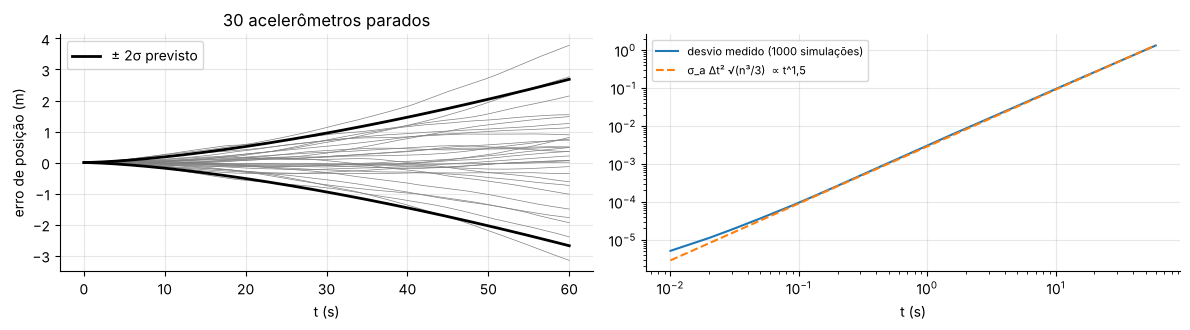

OK   desvio da velocidade após 60 s (teoria √n):  diferença relativa máxima = 3.11e-02
OK   desvio da posição após 60 s (teoria √(n³/3)):  diferença relativa máxima = 1.56e-02
depois de 1 minuto, o erro típico de posição é 1.34 m; depois de 10 minutos seria 42 m


In [3]:
dt, n_passos, sig_a, n_mc = 0.01, 6000, 0.05, 1000           # 100 Hz por 60 s, ruído de 0,05 m/s²
ruido = sig_a * rng.standard_normal((n_mc, n_passos))
v_err = np.cumsum(ruido, axis=1) * dt                          # integra uma vez
x_err = np.cumsum(v_err, axis=1) * dt                          # integra de novo
n = np.arange(1, n_passos + 1)
sv_teo, sx_teo = sig_a * dt * np.sqrt(n), sig_a * dt**2 * np.sqrt(n**3 / 3)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
for k in range(30):
    ax[0].plot(n * dt, x_err[k], lw=.5, color="gray")
ax[0].plot(n * dt, 2 * sx_teo, "k", lw=2, label="± 2σ previsto"); ax[0].plot(n * dt, -2 * sx_teo, "k", lw=2)
ax[0].set_xlabel("t (s)"); ax[0].set_ylabel("erro de posição (m)"); ax[0].legend(); ax[0].set_title("30 acelerômetros parados")
ax[1].loglog(n * dt, x_err.std(0), label="desvio medido (1000 simulações)")
ax[1].loglog(n * dt, sx_teo, "--", label="σ_a Δt² √(n³/3)  ∝ t^1,5")
ax[1].set_xlabel("t (s)"); ax[1].legend(fontsize=8); plt.tight_layout(); plt.show()
confere("desvio da velocidade após 60 s (teoria √n)", v_err[:, -1].std(), sv_teo[-1], tol=0.06, relativo=True)
confere("desvio da posição após 60 s (teoria √(n³/3))", x_err[:, -1].std(), sx_teo[-1], tol=0.06, relativo=True)
print(f"depois de 1 minuto, o erro típico de posição é {sx_teo[-1]:.2f} m; depois de 10 minutos seria {sig_a * dt**2 * np.sqrt((60000)**3 / 3):.0f} m")

**Leitura.** Um acelerômetro razoável, sozinho, erra a posição em mais de um metro depois de um minuto, e em dezenas de metros depois de dez. Por isso um drone **funde** o acelerômetro com outras medidas (GPS, câmera). Fazer essa fusão de modo ótimo é o trabalho do filtro de Kalman.

(As conferências usam tolerância de 6% porque o desvio estimado com 1000 simulações tem um erro estatístico de uns 2%.)

---

## 2. Dinâmica: o bloco com mola e atrito viscoso

Um bloco de massa $m$, preso a uma mola de constante $k$, com atrito viscoso de coeficiente $c$ (força proporcional à velocidade, como num amortecedor) e sob uma força externa $u(t)$. A segunda lei de Newton dá

$$m\ddot x=-kx-c\dot x+u(t).$$

Sem força externa, há três regimes, conforme o sinal de $c^2-4mk$:
- **subamortecido** ($c^2<4mk$): oscila, com amplitude decaindo;
- **crítico** ($c^2=4mk$): volta ao repouso o mais rápido possível, sem oscilar;
- **superamortecido** ($c^2>4mk$): volta devagar, sem oscilar.

O `sympy` resolve a equação diferencial nos três casos.

subamortecido    (c = 2/5):  x(t) = (sqrt(11)*sin(3*sqrt(11)*t/5)/33 + cos(3*sqrt(11)*t/5))*exp(-t/5)
crítico          (c = 4):  x(t) = (2*t + 1)*exp(-2*t)


superamortecido  (c = 10):  x(t) = ((21 - 5*sqrt(21))*exp(t*(5 - sqrt(21))) + (21 + 5*sqrt(21))*exp(t*(sqrt(21) + 5)))*exp(-10*t)/42


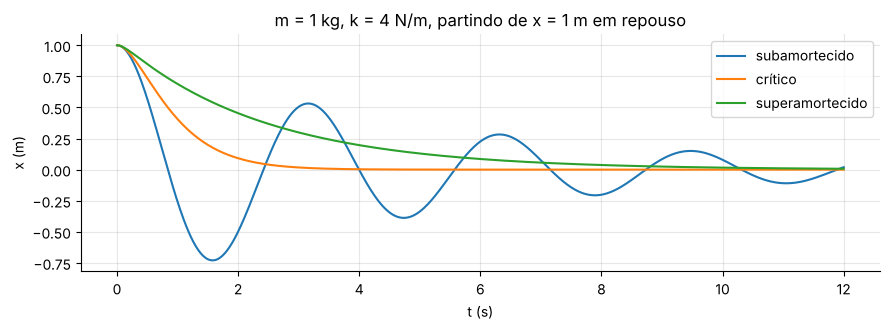


com força constante de 2 N:  x(t) = (33*exp(t/5) - sqrt(11)*sin(3*sqrt(11)*t/5) - 33*cos(3*sqrt(11)*t/5))*exp(-t/5)/66
posição final (t → ∞): 1/2  = F/k, como na seção 1 do notebook (b)


In [4]:
tt = sp.Symbol("t", nonnegative=True)
x = sp.Function("x")
m_, k_ = 1, 4
sols = {}
for nome, c_ in [("subamortecido", sp.Rational(2, 5)), ("crítico", 4), ("superamortecido", 10)]:
    edo = sp.Eq(m_ * x(tt).diff(tt, 2) + c_ * x(tt).diff(tt) + k_ * x(tt), 0)
    s = sp.dsolve(edo, ics={x(0): 1, x(tt).diff(tt).subs(tt, 0): 0})
    sols[nome] = s.rhs
    print(f"{nome:16s} (c = {c_}):  x(t) = {sp.simplify(s.rhs)}")

ts = np.linspace(0, 12, 600)
fig, ax = plt.subplots(figsize=(9, 3.4))
for nome, expr in sols.items():
    ax.plot(ts, sp.lambdify(tt, expr, "numpy")(ts), label=nome)
ax.set_xlabel("t (s)"); ax.set_ylabel("x (m)"); ax.legend(); ax.set_title("m = 1 kg, k = 4 N/m, partindo de x = 1 m em repouso")
plt.tight_layout(); plt.show()

# com uma força em degrau: u(t) = 2 N a partir de t = 0
edo_f = sp.Eq(x(tt).diff(tt, 2) + sp.Rational(2, 5) * x(tt).diff(tt) + 4 * x(tt), 2)
x_degrau = sp.dsolve(edo_f, ics={x(0): 0, x(tt).diff(tt).subs(tt, 0): 0}).rhs
print("\ncom força constante de 2 N:  x(t) =", sp.simplify(x_degrau))
print("posição final (t → ∞):", sp.limit(x_degrau, tt, sp.oo), " = F/k, como na seção 1 do notebook (b)")

---

## 3. Euler e Runge–Kutta

Os métodos numéricos trabalham com a equação na forma de **primeira ordem**, com o estado $\mathbf y=(x,v)$:

$$\dot{\mathbf y}=\mathbf f(t,\mathbf y)=\begin{bmatrix}v\\(-kx-cv+u(t))/m\end{bmatrix}.$$

Três métodos com passo $h$:
- **Euler explícito:** $\mathbf y_{n+1}=\mathbf y_n+h\,\mathbf f(t_n,\mathbf y_n)$. Usa a inclinação do começo do passo. Erro global proporcional a $h$ (ordem 1).
- **Euler semi-implícito (simplético):** atualiza primeiro a velocidade e usa a velocidade **nova** para atualizar a posição. Também tem ordem 1, mas conserva (quase) a energia de sistemas sem atrito.
- **Runge–Kutta de ordem 4 (RK4):** calcula quatro inclinações dentro do passo e faz uma média ponderada,
$$\mathbf k_1=\mathbf f(t_n,\mathbf y_n),\ \ \mathbf k_2=\mathbf f(t_n+\tfrac h2,\mathbf y_n+\tfrac h2\mathbf k_1),\ \ \mathbf k_3=\mathbf f(t_n+\tfrac h2,\mathbf y_n+\tfrac h2\mathbf k_2),\ \ \mathbf k_4=\mathbf f(t_n+h,\mathbf y_n+h\mathbf k_3),$$
$$\mathbf y_{n+1}=\mathbf y_n+\tfrac h6(\mathbf k_1+2\mathbf k_2+2\mathbf k_3+\mathbf k_4).$$
Erro global proporcional a $h^4$: dividir o passo por 2 divide o erro por 16.

A ordem não se acredita, **mede-se**: resolvemos com vários passos, comparamos com a solução exata do `sympy` e medimos a inclinação da reta no gráfico log-log.

Euler                  ordem medida = 1.10
Euler semi-implícito   ordem medida = 1.02
RK4                    ordem medida = 4.00


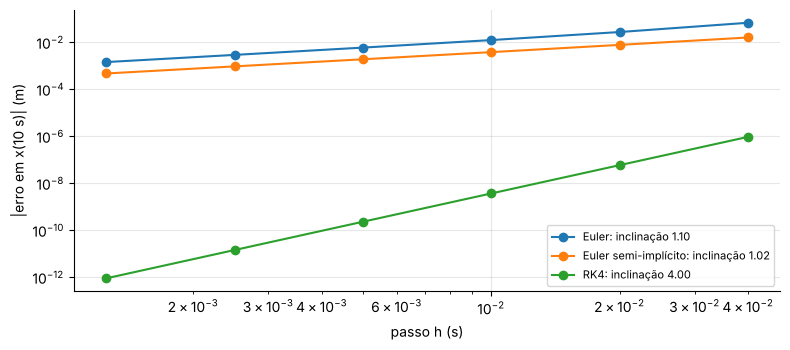

OK   ordem do Euler ≈ 1:  diferença máxima = 1.01e-01
OK   ordem do RK4 ≈ 4:  diferença máxima = 7.94e-04
OK   scipy (DOP853) concorda com o sympy:  diferença máxima = 1.40e-13


In [5]:
M, KMOLA, CAT = 1.0, 4.0, 0.4

def f_bloco(t, y, u=lambda t: 0.0):
    x, v = y
    return np.array([v, (-KMOLA * x - CAT * v + u(t)) / M])

def euler(f, y0, T, h):
    y = np.array(y0, float)
    for i in range(int(round(T / h))):
        y = y + h * f(i * h, y)
    return y

def euler_semi(y0, T, h, k=KMOLA, c=CAT, m=M):
    x, v = y0
    for _ in range(int(round(T / h))):
        v = v + h * (-k * x - c * v) / m      # primeiro a velocidade...
        x = x + h * v                          # ...e a posição com a velocidade NOVA
    return np.array([x, v])

def rk4_passo(f, t, y, h):
    k1 = f(t, y)
    k2 = f(t + h / 2, y + h / 2 * k1)
    k3 = f(t + h / 2, y + h / 2 * k2)
    k4 = f(t + h, y + h * k3)
    return y + h / 6 * (k1 + 2 * k2 + 2 * k3 + k4)

def rk4(f, y0, T, h):
    y = np.array(y0, float)
    for i in range(int(round(T / h))):
        y = rk4_passo(f, i * h, y, h)
    return y

T_fim = 10.0
x_exato = float(sols["subamortecido"].subs(tt, T_fim))
hs = np.array([0.04, 0.02, 0.01, 0.005, 0.0025, 0.00125])
erros = {"Euler": [abs(euler(f_bloco, [1, 0], T_fim, h)[0] - x_exato) for h in hs],
         "Euler semi-implícito": [abs(euler_semi([1, 0], T_fim, h)[0] - x_exato) for h in hs],
         "RK4": [abs(rk4(f_bloco, [1, 0], T_fim, h)[0] - x_exato) for h in hs]}
fig, ax = plt.subplots(figsize=(8, 3.6))
for nome, e in erros.items():
    incl = np.polyfit(np.log(hs), np.log(e), 1)[0]
    ax.loglog(hs, e, "o-", label=f"{nome}: inclinação {incl:.2f}")
    print(f"{nome:22s} ordem medida = {incl:.2f}")
ax.set_xlabel("passo h (s)"); ax.set_ylabel("|erro em x(10 s)| (m)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
confere("ordem do Euler ≈ 1", np.polyfit(np.log(hs), np.log(erros["Euler"]), 1)[0], 1.0, tol=0.15)
confere("ordem do RK4 ≈ 4", np.polyfit(np.log(hs), np.log(erros["RK4"]), 1)[0], 4.0, tol=0.15)
sol_ref = solve_ivp(f_bloco, (0, T_fim), [1.0, 0.0], method="DOP853", rtol=1e-12, atol=1e-14)
confere("scipy (DOP853) concorda com o sympy", sol_ref.y[0, -1], x_exato, tol=1e-10)

### Energia: o que cada método faz com um oscilador sem atrito

Sem atrito ($c=0$), a energia $E=\tfrac12mv^2+\tfrac12kx^2$ deveria ficar constante para sempre. Integrando por 200 s, com passo $h=0{,}05$ s:

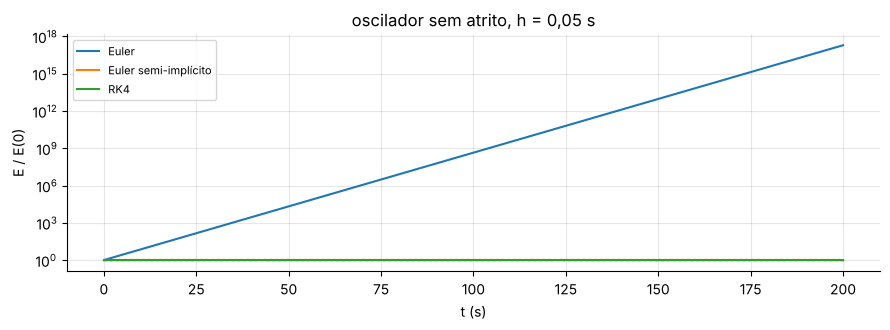

Euler                  E(200 s)/E(0) = 1.92972e+17
Euler semi-implícito   E(200 s)/E(0) = 0.969364
RK4                    E(200 s)/E(0) = 0.999945


In [6]:
def energia(y): return 0.5 * M * y[1]**2 + 0.5 * KMOLA * y[0]**2
f_sem_atrito = lambda t, y: np.array([y[1], -KMOLA * y[0] / M])
h, T_longo = 0.05, 200.0
traj = {"Euler": [], "Euler semi-implícito": [], "RK4": []}
ye, ys, yr = np.array([1.0, 0.0]), (1.0, 0.0), np.array([1.0, 0.0])
for i in range(int(T_longo / h)):
    ye = ye + h * f_sem_atrito(0, ye)
    ys = euler_semi(ys, h, h, c=0.0)
    yr = rk4_passo(f_sem_atrito, 0, yr, h)
    for nome, y in zip(traj, [ye, ys, yr]):
        traj[nome].append(energia(y) / energia([1.0, 0.0]))
fig, ax = plt.subplots(figsize=(9, 3.4))
tempo = np.arange(1, int(T_longo / h) + 1) * h
for nome, E in traj.items():
    ax.semilogy(tempo, E, label=nome)
ax.set_xlabel("t (s)"); ax.set_ylabel("E / E(0)"); ax.legend(fontsize=8); ax.set_title("oscilador sem atrito, h = 0,05 s")
plt.tight_layout(); plt.show()
for nome, E in traj.items():
    print(f"{nome:22s} E(200 s)/E(0) = {E[-1]:.6g}")

**Leitura.**
- O **Euler explícito** cria energia do nada: a cada passo, a energia é multiplicada por $1+h^2k/m$, e em 200 s ela cresce por um fator astronômico.
- O **RK4** perde energia devagar: menos de um décimo de milésimo em 200 s, com este passo.
- O **semi-implícito**, apesar de ter só ordem 1, mantém a energia **oscilando em torno do valor certo**, sem deriva. Ele preserva uma estrutura da física (é "simplético"), e não só a precisão local.

A lição atravessa a série: **um método numérico pode ser preciso e ainda assim desrespeitar a estrutura do problema**. Nos domínios com rotação, a estrutura a respeitar é outra: a rotação tem de continuar sendo uma rotação. É para isso que serve o RKMK.

---

## 4. Atrito seco (de Coulomb)

Um bloco que desliza sobre uma mesa sente uma força de atrito de módulo **constante**, $\mu mg$, sempre contra o movimento:

$$m\ddot x=-kx-\mu mg\,\mathrm{sinal}(\dot x).$$

O lado direito é **descontínuo** quando a velocidade troca de sinal, e o bloco pode **parar de vez** se a mola não vencer o atrito estático ($|kx|\le\mu mg$). Não há uma fórmula fechada única para todo o movimento, e o `sympy` não resolve a equação inteira.

**Mas há um resultado exato para conferir.** Durante cada meia oscilação, o atrito tem sinal constante e o movimento é um oscilador com centro deslocado de $\pm\mu mg/k$. Por isso, a cada meia oscilação, a amplitude **diminui de $2\mu mg/k$**, uma queda **linear**, e não exponencial como no atrito viscoso. O bloco para na primeira vez em que a amplitude fica abaixo de $\mu mg/k$.

picos simulados : [ 1.      -0.75475  0.5095  -0.26425  0.019  ]
picos previstos : [ 1.      -0.75475  0.5095  -0.26425  0.019  ]
OK   cada meia oscilação perde 2μmg/k de amplitude:  diferença máxima = 1.40e-08
o bloco para em t = 6.283 s, em x = 0.0190 m (zona morta: |x| ≤ 0.1226 m)


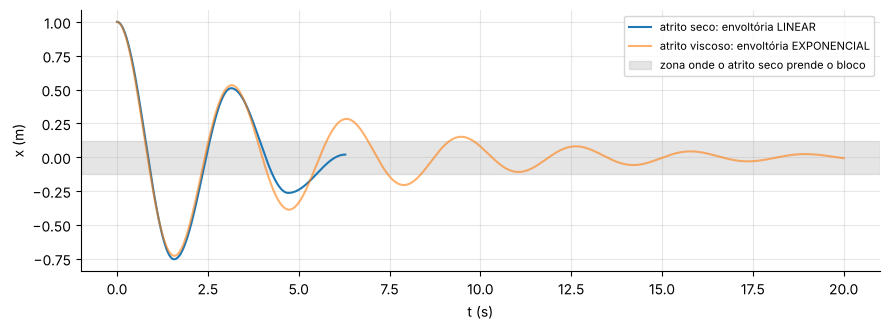

In [7]:
mu, gr = 0.05, 9.81
delta = mu * M * gr / KMOLA                   # meia "zona morta": |x| <= delta não vence o atrito

def simula_coulomb(x0, h=1e-4, T=20.0):
    y = np.array([x0, 0.0]); xs_, picos, parado = [x0], [x0], None
    f = lambda t, y: np.array([y[1], (-KMOLA * y[0] - mu * M * gr * np.sign(y[1] if y[1] != 0 else -y[0])) / M])
    for i in range(int(T / h)):
        y_novo = rk4_passo(f, i * h, y, h)
        if y[1] != 0 and np.sign(y_novo[1]) != np.sign(y[1]):        # a velocidade trocou de sinal: um pico
            picos.append(y_novo[0])
            if abs(KMOLA * y_novo[0]) <= mu * M * gr:                 # a mola não vence o atrito: o bloco para
                y_novo = np.array([y_novo[0], 0.0]); parado = (i + 1) * h
        y = y_novo; xs_.append(y[0])
        if parado is not None:
            break
    return np.array(xs_), np.array(picos), parado

xs_c, picos, t_parada = simula_coulomb(1.0)
previstos = [(1.0 - 2 * delta * j) * (-1)**j for j in range(len(picos))]
print("picos simulados :", np.round(picos, 5))
print("picos previstos :", np.round(previstos, 5))
confere("cada meia oscilação perde 2μmg/k de amplitude", picos, previstos, tol=2e-3)
print(f"o bloco para em t = {t_parada:.3f} s, em x = {xs_c[-1]:.4f} m (zona morta: |x| ≤ {delta:.4f} m)")

y_v = solve_ivp(f_bloco, (0, 20), [1.0, 0.0], t_eval=np.linspace(0, 20, 2000), rtol=1e-9).y[0]
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(np.arange(len(xs_c)) * 1e-4, xs_c, label="atrito seco: envoltória LINEAR")
ax.plot(np.linspace(0, 20, 2000), y_v, alpha=.6, label="atrito viscoso: envoltória EXPONENCIAL")
ax.axhspan(-delta, delta, color="gray", alpha=.2, label="zona onde o atrito seco prende o bloco")
ax.set_xlabel("t (s)"); ax.set_ylabel("x (m)"); ax.legend(fontsize=8); plt.tight_layout(); plt.show()

**Detalhes.** O RK4 é um método de ordem 4 para funções **suaves**. Com o sinal descontínuo, a ordem cai no passo em que a velocidade troca de sinal; por isso o passo é pequeno ($10^{-4}$ s). A conferência aceita $2\times10^{-3}$ por segurança; o erro obtido é muito menor porque, com este passo, a troca de sinal acontece quase exatamente no fim de um passo. Um tratamento profissional localizaria o instante exato da troca de sinal (detecção de eventos, como em `solve_ivp(..., events=...)`): exercício 3.

---

## 5. Espaço de estados e discretização exata: de onde vêm F e Q

Com o estado $\mathbf y=(x,v)$, a equação linear do bloco é

$$\dot{\mathbf y}=\mathbf A\mathbf y+\mathbf B u,\qquad \mathbf A=\begin{bmatrix}0&1\\-k/m&-c/m\end{bmatrix},\quad \mathbf B=\begin{bmatrix}0\\1/m\end{bmatrix}.$$

Se a força $u$ é constante durante um intervalo $\Delta t$ (como a saída de um computador que atualiza a força a cada $\Delta t$), a solução **exata** no fim do intervalo é

$$\mathbf y_{n+1}=\underbrace{e^{\mathbf A\Delta t}}_{\mathbf F}\mathbf y_n+\underbrace{\int_0^{\Delta t}e^{\mathbf As}\,ds\,\mathbf B}_{\mathbf G}\,u_n .$$

A exponencial de **matriz** é a mesma série da seção 4 do notebook (a), agora com matrizes. As duas matrizes saem de uma única exponencial de uma matriz aumentada (truque de Van Loan): $\exp\!\Big(\begin{bmatrix}\mathbf A&\mathbf B\\0&0\end{bmatrix}\Delta t\Big)=\begin{bmatrix}\mathbf F&\mathbf G\\0&1\end{bmatrix}$.

**E o ruído.** Se, além de $u$, o bloco leva "empurrões" aleatórios (vento, vibração), modelados como ruído branco de intensidade $q$, a covariância que esse ruído acumula durante $\Delta t$ é

$$\mathbf Q=\int_0^{\Delta t}e^{\mathbf As}\,\mathbf B\,q\,\mathbf B^\top e^{\mathbf A^\top s}\,ds,$$

também obtida por uma exponencial aumentada. **$\mathbf F$ e $\mathbf Q$ são exatamente as matrizes de predição do filtro de Kalman**: $\hat{\mathbf y}\leftarrow\mathbf F\hat{\mathbf y}+\mathbf Gu$, $\ \mathbf P\leftarrow\mathbf F\mathbf P\mathbf F^\top+\mathbf Q$. As conferências abaixo comparam $\mathbf F,\mathbf G$ com a solução exata do `sympy` e $\mathbf Q$ com uma simulação de Monte Carlo.

In [8]:
A = np.array([[0.0, 1.0], [-KMOLA / M, -CAT / M]]); B = np.array([[0.0], [1.0 / M]])
DT = 0.1

def discretiza(A, B, dt, q=None):
    n, m = A.shape[0], B.shape[1]
    Maug = np.zeros((n + m, n + m)); Maug[:n, :n] = A; Maug[:n, n:] = B
    E = expm(Maug * dt); F, G = E[:n, :n], E[:n, n:]
    if q is None:
        return F, G
    V = np.zeros((2 * n, 2 * n)); V[:n, :n] = -A; V[:n, n:] = B @ B.T * q; V[n:, n:] = A.T
    W = expm(V * dt); Q = F @ W[:n, n:]
    return F, G, 0.5 * (Q + Q.T)

F, G = discretiza(A, B, DT)
print("F =\n", F, "\nG =\n", G)

# conferência 1: simular com F, G e força em degrau de 2 N deve coincidir com a solução exata do sympy
y = np.zeros(2); x_disc = [0.0]
for _ in range(100):
    y = F @ y + G[:, 0] * 2.0; x_disc.append(y[0])
x_sym = sp.lambdify(tt, x_degrau, "numpy")(np.arange(101) * DT)
confere("simulação com F e G = solução exata do sympy, nos instantes de amostragem", x_disc, x_sym, tol=1e-12)

# conferência 2: Q contra Monte Carlo com passos muito finos (Euler–Maruyama)
q = 0.5
F, G, Q = discretiza(A, B, DT, q)
n_mc, sub = 20000, 400; h = DT / sub
Y = np.zeros((n_mc, 2))
for _ in range(sub):
    dW = np.sqrt(q * h) * rng.standard_normal(n_mc)
    Y = Y + h * (Y @ A.T) + np.outer(dW, B[:, 0])
print("\nQ (fórmula) =\n", Q, "\nQ (Monte Carlo) =\n", np.cov(Y.T))
confere("Q da fórmula = covariância de Monte Carlo", np.cov(Y.T), Q, tol=0.05, relativo=True)

F =
 [[ 0.98033   0.097374]
 [-0.389497  0.94138 ]] 
G =
 [[0.004918]
 [0.097374]]
OK   simulação com F e G = solução exata do sympy, nos instantes de amostragem:  diferença máxima = 7.77e-16



Q (fórmula) =
 [[0.00016  0.00237 ]
 [0.00237  0.047423]] 
Q (Monte Carlo) =
 [[0.000158 0.00234 ]
 [0.00234  0.047016]]
OK   Q da fórmula = covariância de Monte Carlo:  diferença relativa máxima = 8.59e-03


**Leitura.** A discretização é **exata**: não há erro de passo, ao contrário de Euler e RK4. Isso só é possível porque a equação é linear; com a mola de Duffing ou o atrito seco, volta-se ao RK4 (ou se lineariza, e é aí que nasce o filtro de Kalman estendido).

## 6. RK4 hoje, RKMK nos próximos domínios

Repare como o RK4 combina as inclinações: $\mathbf y_n+\tfrac h2\mathbf k_1$, $\ \mathbf y_n+h\mathbf k_3$ e a média final. Tudo isso é **somar** um incremento ao estado, isto é, $\boxplus$ em ℝ.

Nos domínios com rotação, somar um incremento a uma rotação não dá uma rotação. O **RKMK** (Runge–Kutta–Munthe-Kaas) resolve isso assim:
- os $\mathbf k_i$ continuam sendo vetores de velocidade, que podem ser somados;
- o estado é atualizado por $\boxplus$, isto é, por `compoe(y, Exp(h·k))`, e não por $+$;
- uma pequena correção (os "colchetes de Lie") compensa o fato de que, quando as rotações não comutam, a ordem dos incrementos importa.

Em ℝ, $\boxplus$ é a soma e os colchetes são zero: **o RKMK é exatamente o RK4**. Essa coincidência será conferida explicitamente no domínio IV, e a diferença aparecerá a partir do domínio V.

---

## 7. Exercícios

1. **Ordem do semi-implícito.** No gráfico da seção 3, o Euler semi-implícito também tem ordem 1. Por que, então, ele se comporta tão melhor em energia? Calcule o que ele conserva exatamente: a quantidade $\tfrac12mv^2+\tfrac12kx^2+\tfrac12hkxv$.
2. **Passo adaptativo.** Use `solve_ivp` com `method="RK45"` e diferentes tolerâncias `rtol`. Plote o erro contra o número de avaliações de $\mathbf f$, junto com o RK4 de passo fixo. Qual é mais eficiente?
3. **Eventos.** Refaça o atrito seco com `solve_ivp(..., events=...)`, parando a integração exatamente quando $v=0$ e recomeçando com o novo sinal do atrito. A conferência dos picos melhora para que tolerância?
4. **Mola de Duffing dinâmica.** Acrescente $k_3x^3$ à força da mola. Não há solução simbólica simples. Verifique a ordem do RK4 contra uma solução de referência com passo muito pequeno.
5. **Q pequeno.** Para $\Delta t$ pequeno, $\mathbf Q\approx\begin{bmatrix}q\Delta t^3/3&q\Delta t^2/2\\q\Delta t^2/2&q\Delta t\end{bmatrix}/m^2$. Deduza essa aproximação e confira-a contra `discretiza` para $\Delta t=10^{-3}$. Compare com as fórmulas da seção 1.